# TensorFlow Lab: Tasks 1–4
Run the **setup cell first**, then each task in order. Every task cell also has its own imports, so you can rerun a task by itself after a kernel restart.

---
## Task 1: Tensor Manipulations & Reshaping

In [16]:
import tensorflow as tf

tf.random.set_seed(42)

# 1. Create a random tensor of shape (4, 6)
x = tf.random.uniform((4, 6), minval=0, maxval=10, dtype=tf.float32)
print("Original tensor:\n", x.numpy().round(2))

# 2. Rank and shape using TensorFlow functions
print("\n--- Original ---")
print("Rank :", tf.rank(x).numpy())
print("Shape:", tf.shape(x).numpy())

# 3a. Reshape (4, 6) -> (2, 3, 4)   [4*6 = 24 = 2*3*4, so the element count matches]
x_reshaped = tf.reshape(x, (2, 3, 4))
print("\n--- After reshape ---")
print("Rank :", tf.rank(x_reshaped).numpy())
print("Shape:", tf.shape(x_reshaped).numpy())

# 3b. Transpose (2, 3, 4) -> (3, 2, 4) by swapping axis 0 and axis 1
x_transposed = tf.transpose(x_reshaped, perm=[1, 0, 2])
print("\n--- After transpose ---")
print("Rank :", tf.rank(x_transposed).numpy())
print("Shape:", tf.shape(x_transposed).numpy())

# 4. Broadcast a smaller tensor of shape (1, 4) and add it
small = tf.constant([[1.0, 2.0, 3.0, 4.0]])          # shape (1, 4)
print("\n--- Broadcasting ---")
print("Small tensor shape      :", tf.shape(small).numpy())

result = x_transposed + small                          # implicit broadcasting
print("Result shape after add  :", tf.shape(result).numpy())

# Same thing done explicitly, to prove what broadcasting did
small_expanded = tf.broadcast_to(small, tf.shape(x_transposed))
print("Explicit broadcast shape:", tf.shape(small_expanded).numpy())
print("Implicit == explicit?   :", bool(tf.reduce_all(tf.equal(result, x_transposed + small_expanded))))

Original tensor:
 [[6.65 4.41 3.53 4.64 0.34 6.85]
 [7.4  8.72 2.26 2.23 3.1  7.22]
 [1.33 5.48 5.75 9.   0.09 5.21]
 [6.35 1.99 7.29 5.46 1.08 6.77]]

--- Original ---
Rank : 2
Shape: [4 6]

--- After reshape ---
Rank : 3
Shape: [2 3 4]

--- After transpose ---
Rank : 3
Shape: [3 2 4]

--- Broadcasting ---
Small tensor shape      : [1 4]
Result shape after add  : [3 2 4]
Explicit broadcast shape: [3 2 4]
Implicit == explicit?   : True


### 5. How broadcasting works in TensorFlow

When two tensors with different shapes meet in an element-wise operation (`+`, `-`, `*`, `/`), TensorFlow compares their shapes **starting from the rightmost dimension**. Two dimensions are compatible if they are **equal**, or if **one of them is 1**. A size-1 dimension is stretched to match the other, and a missing leading dimension is treated as 1.

```
x_transposed : (3, 2, 4)
small        :    (1, 4)   -> treated as (1, 1, 4)
result       : (3, 2, 4)
```

Last dimension: 4 vs 4, equal. Middle dimension: 2 vs 1, so the 1 stretches to 2. First dimension: 3 vs missing (treated as 1), so it stretches to 3.

The row `[1, 2, 3, 4]` therefore gets added to all 3 × 2 = 6 length-4 vectors. No data is physically copied, which is why broadcasting is memory-efficient. `tf.broadcast_to` performs the same expansion explicitly, and the check above confirms both give identical results. If shapes are incompatible, for example `(3, 2, 4) + (1, 3)`, TensorFlow raises an `InvalidArgumentError`.

---
## Task 2: Loss Functions: MSE vs Categorical Cross-Entropy

Original         ->  MSE: 0.0489   |   Cross-Entropy: 0.3635
Slightly better  ->  MSE: 0.0156   |   Cross-Entropy: 0.1839
Slightly worse   ->  MSE: 0.1289   |   Cross-Entropy: 0.7068


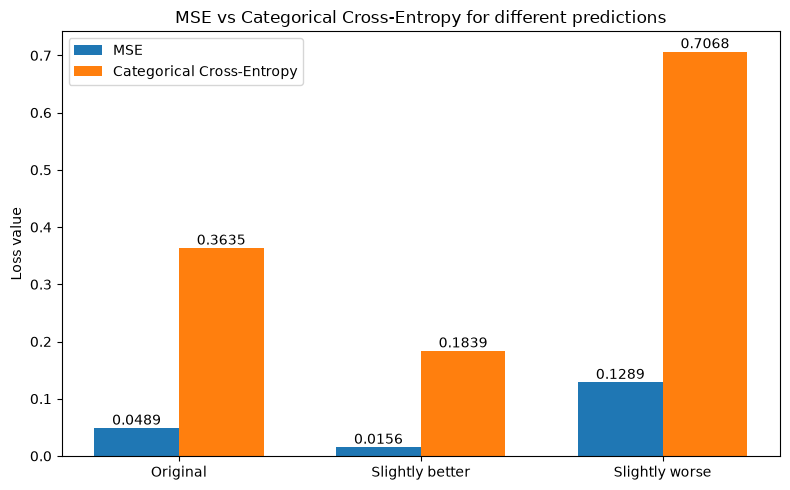

In [11]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# 1. True labels (one-hot, 3 samples x 3 classes) and model predictions (probabilities)
y_true = tf.constant([[1, 0, 0],
                      [0, 1, 0],
                      [0, 0, 1]], dtype=tf.float32)

predictions = {
    "Original":        tf.constant([[0.70, 0.20, 0.10],
                                    [0.10, 0.80, 0.10],
                                    [0.20, 0.20, 0.60]]),
    # 3. Slightly modified predictions (each row still sums to 1)
    "Slightly better": tf.constant([[0.80, 0.15, 0.05],
                                    [0.05, 0.90, 0.05],
                                    [0.10, 0.10, 0.80]]),
    "Slightly worse":  tf.constant([[0.50, 0.30, 0.20],
                                    [0.20, 0.60, 0.20],
                                    [0.30, 0.30, 0.40]]),
}

# 2. Loss functions
mse_fn = tf.keras.losses.MeanSquaredError()
cce_fn = tf.keras.losses.CategoricalCrossentropy()

mse_values, cce_values = [], []
for name, y_pred in predictions.items():
    mse = float(mse_fn(y_true, y_pred).numpy())
    cce = float(cce_fn(y_true, y_pred).numpy())
    mse_values.append(mse)
    cce_values.append(cce)
    print(f"{name:<16} ->  MSE: {mse:.4f}   |   Cross-Entropy: {cce:.4f}")

# 4. Bar chart comparing the two losses
labels = list(predictions.keys())
pos = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
bars_mse = ax.bar(pos - width/2, mse_values, width, label="MSE")
bars_cce = ax.bar(pos + width/2, cce_values, width, label="Categorical Cross-Entropy")
ax.bar_label(bars_mse, fmt="%.4f")
ax.bar_label(bars_cce, fmt="%.4f")
ax.set_xticks(pos)
ax.set_xticklabels(labels)
ax.set_ylabel("Loss value")
ax.set_title("MSE vs Categorical Cross-Entropy for different predictions")
ax.legend()
plt.tight_layout()
plt.show()

**Observation:** Putting more probability on the correct class lowers both losses, and putting less raises both. Cross-entropy reacts more strongly because it takes the log of the probability assigned to the true class, so confident mistakes get punished hard. MSE only averages small squared differences across all classes. That's why cross-entropy is the standard loss for classification and MSE for regression.

---
## Task 3: Train MNIST with Adam vs SGD

In [12]:
import tensorflow as tf
import matplotlib.pyplot as plt

# 1. Load and normalize MNIST (pixel values 0-255 -> 0-1)
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0
print("Train:", x_train.shape, " Test:", x_test.shape)

def build_model():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(128, activation="relu"),
        tf.keras.layers.Dense(10, activation="softmax"),
    ])

EPOCHS = 5
BATCH_SIZE = 64

# 2. Train one model per optimizer (same architecture, same starting seed)
optimizers = {
    "Adam": lambda: tf.keras.optimizers.Adam(learning_rate=0.001),
    "SGD":  lambda: tf.keras.optimizers.SGD(learning_rate=0.01),
}

histories = {}
for name, make_opt in optimizers.items():
    print(f"\n===== Training with {name} =====")
    tf.random.set_seed(42)
    model = build_model()
    model.compile(optimizer=make_opt(),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    histories[name] = model.fit(x_train, y_train,
                                epochs=EPOCHS,
                                batch_size=BATCH_SIZE,
                                validation_split=0.1,
                                verbose=2)
    test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
    print(f"{name} test accuracy: {test_acc:.4f}")

Train: (60000, 28, 28)  Test: (10000, 28, 28)

===== Training with Adam =====
Epoch 1/5
844/844 - 1s - 799us/step - accuracy: 0.9097 - loss: 0.3197 - val_accuracy: 0.9612 - val_loss: 0.1446
Epoch 2/5
844/844 - 0s - 589us/step - accuracy: 0.9577 - loss: 0.1448 - val_accuracy: 0.9707 - val_loss: 0.1042
Epoch 3/5
844/844 - 1s - 617us/step - accuracy: 0.9703 - loss: 0.1011 - val_accuracy: 0.9737 - val_loss: 0.0908
Epoch 4/5
844/844 - 0s - 578us/step - accuracy: 0.9774 - loss: 0.0769 - val_accuracy: 0.9748 - val_loss: 0.0841
Epoch 5/5
844/844 - 0s - 586us/step - accuracy: 0.9827 - loss: 0.0601 - val_accuracy: 0.9763 - val_loss: 0.0816
Adam test accuracy: 0.9747

===== Training with SGD =====
Epoch 1/5
844/844 - 0s - 517us/step - accuracy: 0.7692 - loss: 0.9400 - val_accuracy: 0.8970 - val_loss: 0.4350
Epoch 2/5
844/844 - 0s - 393us/step - accuracy: 0.8830 - loss: 0.4426 - val_accuracy: 0.9150 - val_loss: 0.3229
Epoch 3/5
844/844 - 0s - 404us/step - accuracy: 0.8987 - loss: 0.3689 - val_accu

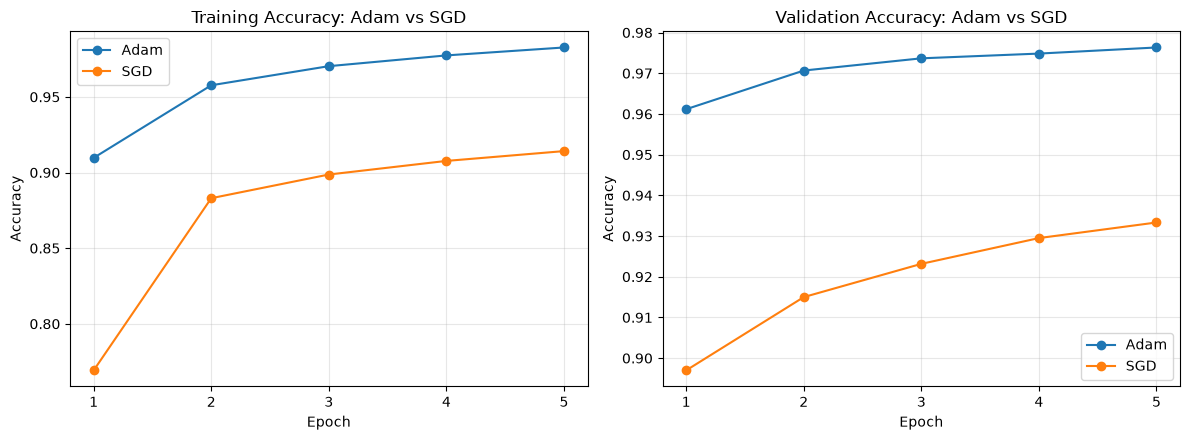

In [13]:
# 3. Compare training and validation accuracy trends
epochs_range = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for name, hist in histories.items():
    axes[0].plot(epochs_range, hist.history["accuracy"], marker="o", label=name)
    axes[1].plot(epochs_range, hist.history["val_accuracy"], marker="o", label=name)

axes[0].set_title("Training Accuracy: Adam vs SGD")
axes[1].set_title("Validation Accuracy: Adam vs SGD")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.set_xticks(list(epochs_range))
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

**What to look for:** Adam usually reaches high accuracy within the first epoch and stays ahead. Plain SGD with learning rate 0.01 starts lower and climbs more slowly but steadily. Adding momentum, e.g. `SGD(learning_rate=0.01, momentum=0.9)`, or training for more epochs narrows the gap. Confirm this against your own plots.

---
## Task 4: Train a Neural Network and Log to TensorBoard
> **Note:** If you get `TBNotInstalledError`, run `%pip install tensorboard` in a cell, then **Kernel → Restart Kernel** and rerun from the setup cell.

In [14]:
import tensorflow as tf
import datetime

# 1. Load and preprocess MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

# 2. Simple neural network
tf.random.set_seed(42)
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(10, activation="softmax"),
])
model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

# TensorBoard logging -> logs/fit/<timestamp>
log_dir = "logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")
tensorboard_cb = tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)

model.fit(x_train, y_train,
          epochs=5,
          batch_size=64,
          validation_data=(x_test, y_test),
          callbacks=[tensorboard_cb],
          verbose=2)

print("\nLogs saved to:", log_dir)

Epoch 1/5
938/938 - 1s - 899us/step - accuracy: 0.9010 - loss: 0.3429 - val_accuracy: 0.9529 - val_loss: 0.1621
Epoch 2/5
938/938 - 1s - 713us/step - accuracy: 0.9517 - loss: 0.1662 - val_accuracy: 0.9666 - val_loss: 0.1120
Epoch 3/5
938/938 - 1s - 681us/step - accuracy: 0.9634 - loss: 0.1238 - val_accuracy: 0.9714 - val_loss: 0.0923
Epoch 4/5
938/938 - 1s - 667us/step - accuracy: 0.9703 - loss: 0.1004 - val_accuracy: 0.9752 - val_loss: 0.0815
Epoch 5/5
938/938 - 1s - 683us/step - accuracy: 0.9744 - loss: 0.0827 - val_accuracy: 0.9764 - val_loss: 0.0768

Logs saved to: logs/fit/20260911-152845


### 3. Launch TensorBoard
Run the cell below to open TensorBoard inside the notebook. In TensorBoard, open the **Scalars** tab and look at `epoch_accuracy` and `epoch_loss`, which show the train and validation runs together.

If the panel shows up blank in JupyterLab, open a terminal in the same folder as this notebook (with the same environment activated) and run `tensorboard --logdir logs/fit`, then go to http://localhost:6006 in your browser.

In [15]:
%load_ext tensorboard
%tensorboard --logdir logs/fit

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 23434), started 0:07:12 ago. (Use '!kill 23434' to kill it.)

### 4.1 Questions to Answer

#### Q1. What patterns do you observe in the training and validation accuracy curves?

Both curves rise every epoch, with smaller gains each time. Training accuracy increased from 90.40% after epoch 1 to 97.48% after epoch 5. The biggest jump came between epochs 1 and 2 (+5.0 percentage points), and the gains then shrank to +1.06, +0.63 and +0.39 points. Validation accuracy started higher, at 95.10%, and reached 97.52%. In the last two epochs it improved by only 0.17 points each, so it is beginning to plateau.

Validation accuracy stayed above training accuracy in all 5 epochs, but the gap shrank from 4.7 points in epoch 1 to only 0.04 points in epoch 5. Validation loss (0.1642 → 0.0784) also stayed below training loss (0.3325 → 0.0827). There are two reasons for this. Dropout (20%) is active only during training, which makes the training task harder. Training metrics are also averaged over the whole epoch while the weights are still improving, whereas validation is measured at the end of each epoch with the final weights.

Validation loss was still decreasing at epoch 5, so there is no sign of overfitting yet. The model generalizes well to unseen digits, and the training and validation curves are close to converging.

#### Q2. How can you use TensorBoard to detect overfitting?

In the **Scalars** tab, the `epoch_loss` and `epoch_accuracy` charts plot the train and validation runs on the same axes. Set the smoothing slider to 0 so short runs aren't distorted. Overfitting shows up as a **growing gap** between the two curves. Training loss keeps decreasing while validation loss stops improving and starts rising. At the same time, training accuracy keeps climbing while validation accuracy flattens or drops.

The epoch where validation loss is lowest is the best stopping point. Past it, the model is memorizing the training data instead of learning general patterns. Because every run is saved in its own folder under `logs/fit/`, TensorBoard can also overlay runs, for example, runs with different epoch counts or with vs without dropout, to compare them directly.

Once overfitting is spotted, the fixes are the `EarlyStopping` callback, dropout, L2 regularization, or simply fewer epochs.

#### Q3. What happens when you increase the number of epochs?

Typically, training accuracy keeps climbing toward 99%+ and training loss keeps shrinking, because the model fits the training set ever more closely. Validation accuracy improves only slightly and then plateaus around 98%, so the extra epochs bring diminishing returns. Validation loss usually reaches its minimum after a handful of epochs and then **starts to rise**, which is overfitting. Training time also grows in proportion to the number of epochs.

The practical approach is to set a generous epoch count and let early stopping pick the best point automatically:

```python
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
```

In this run, validation loss was still decreasing at epoch 5 (0.0825 → 0.0784), so a few more epochs would likely bring small gains before overfitting begins.